# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [3]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\04. Calculus 1 Extra Practice with Integrals - Vol 2'

In [4]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [5]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 02. Area Between Two Curves, Part 2


$$A = \int_a^b [f(x) - g(x)] \, dx$$

### Exercise 1
Area between:

$$f(x) = x^2+4x \quad ; \quad g(x) = x-2 \quad \quad [-3,0]$$




In [ ]:
f = x**2 + 4 * x
g = x - 2
A = sp.Integral(f - g, (x, -3, 0))
answer = A.doit()
display(Math(rf"{sp.latex(A)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

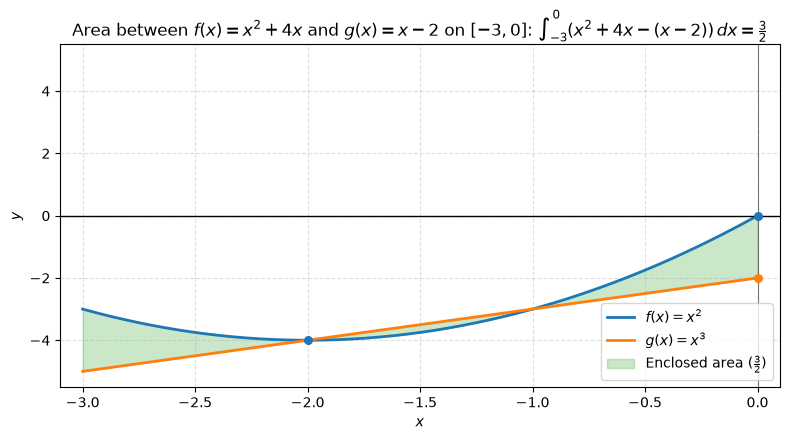

In [ ]:
f_sym = x**2 + 4 * x
g_sym = x - 2

f_num = sp.lambdify(x, f_sym, "numpy")
g_num = sp.lambdify(x, g_sym, "numpy")

# Sample x values across [-2, 1] (plus a small margin to see intersection at x = 1 clearly)
x_vals = np.linspace(-3.0, 0.0, 1000)
y_f = f_num(x_vals)
y_g = g_num(x_vals)

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot both curves
ax.plot(x_vals, y_f, color="tab:blue", linewidth=2, label=r"$f(x) = x^2$")
ax.plot(x_vals, y_g, color="tab:orange", linewidth=2, label=r"$g(x) = x^3$")

# Shade the area between f(x) and g(x) on [-2, 1]
ax.fill_between(
    x_vals,
    y_f,
    y_g,
    color="tab:green",
    alpha=0.25,
    interpolate=True,
    label=r"Enclosed area ($\frac{3}{2}$)",
)

# Mark key points: endpoints and intersection at (0, 0) and (1, 1)
key_x = [-2, 0, 1]
ax.scatter(key_x, f_num(np.array(key_x)), color="tab:blue", zorder=5, s=30)
ax.scatter([0, 1], g_num(np.array([0, 1])), color="tab:orange", zorder=5, s=30)

# Axes and styling
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_xlim(-3.1, 0.1)
# ax.set_xticks([-2, -1, 0, 1])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title(
    r"Area between $f(x) = x^2+4x$ and $g(x) = x-2$ on $[-3, 0]$: $\int_{-3}^{0}(x^2+4x - (x-2))\,dx = \frac{3}{2}$"
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

### Exercise 2
Area between closed region form by:

$$f(x) = x^3 \quad ; \quad g(x) = x^2$$

<img src="./pics/Fig02_01.png" width=600> 

To solve it, we need to find the crossing points, that are the limits of integration.

In [10]:
f = x**3
g = x**2

# Find intersection points of f(x) and g(x)
intersections = sp.solve(sp.Eq(f, g), x)
a, b = sorted(intersections)

# On [0, 1], g(x) = x^2 >= f(x) = x^3, so integrand is g - f
area_integral = sp.Integral(g - f, (x, a, b))
area_exact = area_integral.doit()

display(Math(rf"\text{{Intersections: }} x = {sp.latex(a)}, \, {sp.latex(b)}"))
display(Math(rf"A = {sp.latex(area_integral)} = {sp.latex(area_exact)}"))
print(f"Approximate area: {float(area_exact):.6f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Approximate area: 0.083333


#### Graph 

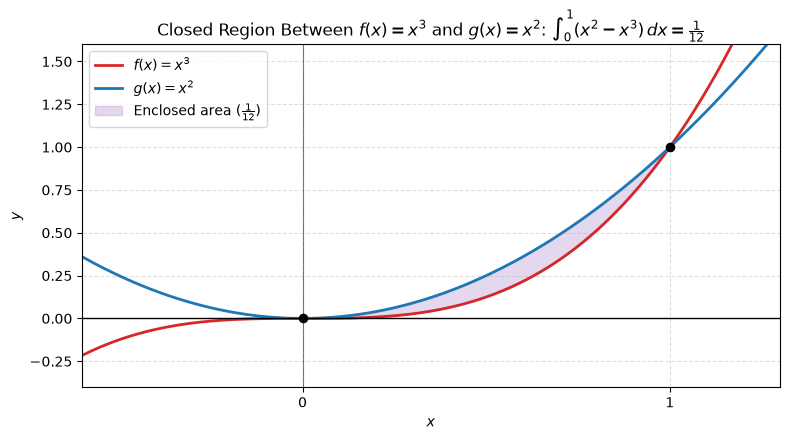

In [ ]:
x = sp.Symbol("x", real=True)
f_sym = x**3
g_sym = x**2

f_num = sp.lambdify(x, f_sym, "numpy")
g_num = sp.lambdify(x, g_sym, "numpy")

# Sample across [-0.6, 1.3] to show full curve behavior, and shade specifically on [0, 1]
x_full = np.linspace(-0.6, 1.3, 1000)
x_region = np.linspace(0.0, 1.0, 500)

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot both curves across the wider domain
ax.plot(x_full, f_num(x_full), color="tab:red", linewidth=2, label=r"$f(x) = x^3$")
ax.plot(x_full, g_num(x_full), color="tab:blue", linewidth=2, label=r"$g(x) = x^2$")

# Shade the enclosed region between x = 0 and x = 1
ax.fill_between(
    x_region,
    f_num(x_region),
    g_num(x_region),
    color="tab:purple",
    alpha=0.25,
    label=r"Enclosed area ($\frac{1}{12}$)",
)

# Mark intersection points (0, 0) and (1, 1)
int_x = np.array([0.0, 1.0])
ax.scatter(int_x, g_num(int_x), color="black", zorder=5, s=35)

# Axes and styling
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_xlim(-0.6, 1.3)
ax.set_ylim(-0.4, 1.6)
ax.set_xticks([0, 1])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title(
    r"Closed Region Between $f(x) = x^3$ and $g(x) = x^2$: $\int_{0}^{1}(x^2 - x^3)\,dx = \frac{1}{12}$"
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()